# Sentiment Intelligence — Classical ML Model Comparison

## Notebook 03

Compare:
- TF-IDF + Logistic Regression
- TF-IDF + Multinomial Naive Bayes
- TF-IDF + Linear SVM

Two feature representations:
1. Word-level TF-IDF (unigrams and bigrams).
2. Combined word-level and character-level TF-IDF.

### Experimental protocol
- Training partition: fit vectorisers and classifiers.
- Validation partition: tune hyperparameters and select configurations.
- Test partition: final performance reporting only.
- Cross-domain partitions: evaluate robustness to unseen review sources.
- All models use exactly the same persisted partitions.

The final production model will not be selected until we also compare the
classical models with the LSTM and BiLSTM experiments.


## 1. Imports and experiment configuration

In [2]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from IPython.display import display
from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)

RANDOM_STATE = 42
ROOT = Path.cwd()

PROJECT_ROOT = next(
    (
        p for p in [ROOT, *ROOT.parents]
        if (p / "data/processed/sentiment/train.csv").exists()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate project root.")

DATA_DIR = PROJECT_ROOT / "data/processed/sentiment"
CROSS_DOMAIN_DIR = DATA_DIR / "cross_domain"

RESULTS_DIR = PROJECT_ROOT / "artifacts/sentiment/classical_ml"
FIGURES_DIR = RESULTS_DIR / "figures"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Scikit-learn:", sklearn.__version__)
print("Project:", PROJECT_ROOT)
print("Results:", RESULTS_DIR)


Scikit-learn: 1.9.1
Project: /home/anupam9k/ai_projects/03_Async_Market_Intelligence_&_Research_Agent
Results: /home/anupam9k/ai_projects/03_Async_Market_Intelligence_&_Research_Agent/artifacts/sentiment/classical_ml


## 2. Load and validate the frozen main partitions

In [3]:
train = pd.read_csv(DATA_DIR / "train.csv")
validation = pd.read_csv(DATA_DIR / "validation.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

PARTITIONS = {
    "train": train,
    "validation": validation,
    "test": test,
}

REQUIRED_COLUMNS = {
    "record_id", "source", "text", "label", "group_id"
}

for name, frame in PARTITIONS.items():
    missing = REQUIRED_COLUMNS - set(frame.columns)
    if missing:
        raise ValueError(f"{name}: missing columns {missing}")

    if frame[list(REQUIRED_COLUMNS)].isna().any().any():
        raise ValueError(f"{name}: null values detected")

    if not set(frame["label"].unique()).issubset({0, 1}):
        raise ValueError(f"{name}: invalid sentiment labels")

    if frame["text"].str.strip().eq("").any():
        raise ValueError(f"{name}: empty sentences detected")

    print(f"{name}: {len(frame)} records")

def assert_no_group_leakage(partitions):
    names = list(partitions)

    for i, first in enumerate(names):
        for second in names[i + 1:]:
            overlap = (
                set(partitions[first]["group_id"])
                & set(partitions[second]["group_id"])
            )
            assert not overlap, (
                f"Duplicate-group leakage: {first} vs {second}"
            )

assert_no_group_leakage(PARTITIONS)

assert len(train) == 1920
assert len(validation) == 480
assert len(test) == 600

print("\nFrozen split integrity: PASSED")


train: 1920 records
validation: 480 records
test: 600 records

Frozen split integrity: PASSED


## 3. Define feature representations

In [4]:
def build_word_vectorizer():
    return TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        analyzer="word",
        token_pattern=r"(?u)\b\w+\b",
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.98,
        sublinear_tf=True,
        dtype=np.float32,
    )


def build_char_vectorizer():
    return TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        analyzer="char_wb",
        ngram_range=(3, 5),
        min_df=2,
        max_df=0.98,
        max_features=50000,
        sublinear_tf=True,
        dtype=np.float32,
    )


def build_features(feature_name):
    if feature_name == "word":
        return build_word_vectorizer()

    if feature_name == "word_char":
        return FeatureUnion(
            [
                ("word", build_word_vectorizer()),
                ("char", build_char_vectorizer()),
            ],
            transformer_weights={
                "word": 1.0,
                "char": 0.5,
            },
        )

    raise ValueError(f"Unknown feature configuration: {feature_name}")


FEATURE_CONFIGS = ["word", "word_char"]

print("Feature configurations:", FEATURE_CONFIGS)


Feature configurations: ['word', 'word_char']


## 4. Define classifiers and hyperparameter grids

In [5]:
MODEL_GRIDS = {
    "LogisticRegression": [
        {"C": 0.1},
        {"C": 1.0},
        {"C": 10.0},
    ],
    "MultinomialNB": [
        {"alpha": 0.1},
        {"alpha": 0.5},
        {"alpha": 1.0},
    ],
    "LinearSVM": [
        {"C": 0.1},
        {"C": 1.0},
        {"C": 10.0},
    ],
}


def build_classifier(model_name, parameters):
    if model_name == "LogisticRegression":
        return LogisticRegression(
            C=parameters["C"],
            solver="lbfgs",
            max_iter=3000,
            random_state=RANDOM_STATE,
        )

    if model_name == "MultinomialNB":
        return MultinomialNB(
            alpha=parameters["alpha"],
        )

    if model_name == "LinearSVM":
        return LinearSVC(
            C=parameters["C"],
            max_iter=10000,
            dual="auto",
            random_state=RANDOM_STATE,
        )

    raise ValueError(f"Unknown model: {model_name}")


def build_pipeline(feature_name, model_name, parameters):
    return Pipeline([
        ("features", build_features(feature_name)),
        ("classifier", build_classifier(model_name, parameters)),
    ])


print("Total candidates:", sum(
    len(parameters)
    for parameters in MODEL_GRIDS.values()
) * len(FEATURE_CONFIGS))


Total candidates: 18


## 5. Evaluation functions

Macro-averaged metrics treat both sentiment classes equally.

ROC-AUC and average precision use continuous prediction scores rather than
thresholded class predictions. Linear SVM uses its decision function.

Inference latency includes vectorisation and prediction.


In [6]:
def get_prediction_scores(model, texts):
    classifier = model.named_steps["classifier"]

    if hasattr(classifier, "predict_proba"):
        return model.predict_proba(texts)[:, 1]

    return model.decision_function(texts)


def calculate_metrics(model, texts, labels):
    predictions = model.predict(texts)
    scores = get_prediction_scores(model, texts)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "balanced_accuracy": balanced_accuracy_score(
            labels, predictions
        ),
        "precision_macro": precision_score(
            labels, predictions,
            average="macro",
            zero_division=0,
        ),
        "recall_macro": recall_score(
            labels, predictions,
            average="macro",
            zero_division=0,
        ),
        "f1_macro": f1_score(
            labels, predictions,
            average="macro",
            zero_division=0,
        ),
        "roc_auc": roc_auc_score(labels, scores),
        "average_precision": average_precision_score(
            labels, scores
        ),
    }


def measure_inference_latency(model, texts, repeats=5):
    measurements = []

    for _ in range(repeats):
        start = time.perf_counter()
        model.predict(texts)
        elapsed = time.perf_counter() - start
        measurements.append(elapsed)

    return (
        float(np.median(measurements))
        * 1000
        / len(texts)
    )


X_train = train["text"].astype(str).tolist()
y_train = train["label"].to_numpy()

X_validation = validation["text"].astype(str).tolist()
y_validation = validation["label"].to_numpy()

X_test = test["text"].astype(str).tolist()
y_test = test["label"].to_numpy()

print("Train:", len(X_train))
print("Validation:", len(X_validation))
print("Test:", len(X_test))


Train: 1920
Validation: 480
Test: 600


## 6. Hyperparameter search using the validation partition

Each feature/model combination is tuned independently.

The best configuration for each combination is selected using:
1. Macro F1 (primary).
2. Balanced accuracy.
3. ROC-AUC.
4. Lower validation inference latency as a tie-breaker.

The test partition is not accessed in this stage.


In [7]:
validation_results = []
best_estimators = {}
best_configurations = {}

for feature_name in FEATURE_CONFIGS:
    for model_name, parameter_grid in MODEL_GRIDS.items():

        experiment_key = f"{feature_name}__{model_name}"
        best_model = None
        best_row = None
        best_rank = None

        print(f"\nTuning: {experiment_key}")

        for parameters in parameter_grid:
            model = build_pipeline(
                feature_name,
                model_name,
                parameters,
            )

            fit_start = time.perf_counter()
            model.fit(X_train, y_train)
            fit_seconds = time.perf_counter() - fit_start

            metrics = calculate_metrics(
                model,
                X_validation,
                y_validation,
            )

            inference_ms = measure_inference_latency(
                model,
                X_validation,
            )

            row = {
                "feature": feature_name,
                "model": model_name,
                "parameters": json.dumps(parameters),
                "fit_seconds": fit_seconds,
                "inference_ms_per_sample": inference_ms,
                **metrics,
            }

            validation_results.append(row)

            rank = (
                metrics["f1_macro"],
                metrics["balanced_accuracy"],
                metrics["roc_auc"],
                -inference_ms,
            )

            if best_rank is None or rank > best_rank:
                best_rank = rank
                best_model = model
                best_row = row

            print(
                f"  {parameters} | "
                f"F1={metrics['f1_macro']:.4f} | "
                f"Accuracy={metrics['accuracy']:.4f} | "
                f"ROC-AUC={metrics['roc_auc']:.4f}"
            )

        best_estimators[experiment_key] = best_model
        best_configurations[experiment_key] = best_row

validation_results_df = pd.DataFrame(validation_results)

validation_results_df = validation_results_df.sort_values(
    ["f1_macro", "balanced_accuracy", "roc_auc"],
    ascending=False,
).reset_index(drop=True)

display(validation_results_df.round(4))

validation_results_df.to_csv(
    RESULTS_DIR / "validation_tuning_results.csv",
    index=False,
)

print("\nValidation tuning results saved.")



Tuning: word__LogisticRegression
  {'C': 0.1} | F1=0.7896 | Accuracy=0.7896 | ROC-AUC=0.8690
  {'C': 1.0} | F1=0.8104 | Accuracy=0.8104 | ROC-AUC=0.8915
  {'C': 10.0} | F1=0.8187 | Accuracy=0.8187 | ROC-AUC=0.8981

Tuning: word__MultinomialNB
  {'alpha': 0.1} | F1=0.8311 | Accuracy=0.8313 | ROC-AUC=0.9058
  {'alpha': 0.5} | F1=0.8269 | Accuracy=0.8271 | ROC-AUC=0.9085
  {'alpha': 1.0} | F1=0.8290 | Accuracy=0.8292 | ROC-AUC=0.9063

Tuning: word__LinearSVM
  {'C': 0.1} | F1=0.8104 | Accuracy=0.8104 | ROC-AUC=0.8910
  {'C': 1.0} | F1=0.8208 | Accuracy=0.8208 | ROC-AUC=0.8972
  {'C': 10.0} | F1=0.7958 | Accuracy=0.7958 | ROC-AUC=0.8773

Tuning: word_char__LogisticRegression
  {'C': 0.1} | F1=0.7979 | Accuracy=0.7979 | ROC-AUC=0.8835
  {'C': 1.0} | F1=0.8145 | Accuracy=0.8146 | ROC-AUC=0.9064
  {'C': 10.0} | F1=0.8353 | Accuracy=0.8354 | ROC-AUC=0.9103

Tuning: word_char__MultinomialNB
  {'alpha': 0.1} | F1=0.8374 | Accuracy=0.8375 | ROC-AUC=0.9246
  {'alpha': 0.5} | F1=0.8269 | Accuracy=

,feature,model,parameters,fit_seconds,inference_ms_per_sample,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,roc_auc,average_precision
0,word_char,MultinomialNB,"{""alpha"": 0.1}",0.2091,0.0710,0.8375,0.8375,0.8383,0.8375,0.8374,0.9246,0.9337
1,word_char,LogisticRegression,"{""C"": 10.0}",0.6242,0.0669,0.8354,0.8354,0.8361,0.8354,0.8353,0.9103,0.9196
2,word_char,LinearSVM,"{""C"": 1.0}",0.2100,0.0671,0.8333,0.8333,0.8337,0.8333,0.8333,0.9089,0.9190
3,word,MultinomialNB,"{""alpha"": 0.1}",0.0378,0.0160,0.8312,0.8312,0.8325,0.8312,0.8311,0.9058,0.9143
4,word,MultinomialNB,"{""alpha"": 1.0}",0.0353,0.0135,0.8292,0.8292,0.8306,0.8292,0.8290,0.9063,0.9163
5,word_char,MultinomialNB,"{""alpha"": 0.5}",0.1924,0.0884,0.8271,0.8271,0.8284,0.8271,0.8269,0.9231,0.9338
6,word,MultinomialNB,"{""alpha"": 0.5}",0.0430,0.0137,0.8271,0.8271,0.8284,0.8271,0.8269,0.9085,0.9181
7,word_char,MultinomialNB,"{""alpha"": 1.0}",0.1903,0.0738,0.8250,0.8250,0.8256,0.8250,0.8249,0.9194,0.9309
8,word_char,LinearSVM,"{""C"": 0.1}",0.2015,0.0814,0.8208,0.8208,0.8212,0.8208,0.8208,0.9066,0.9132
9,word,LinearSVM,"{""C"": 1.0}",0.0410,0.0127,0.8208,0.8208,0.8212,0.8208,0.8208,0.8972,0.9061



Validation tuning results saved.


## 7. Select the best configuration in each model family

The best word-only and word-plus-character configuration is retained for each
classifier.

The overall validation champion is also identified. This is a provisional
selection for later comparison with the neural models.


In [8]:
best_summary = pd.DataFrame(
    list(best_configurations.values())
).sort_values(
    ["f1_macro", "balanced_accuracy", "roc_auc"],
    ascending=False,
).reset_index(drop=True)

display(best_summary.round(4))

champion_row = best_summary.iloc[0]
champion_key = (
    f"{champion_row['feature']}__{champion_row['model']}"
)

print("Validation champion:", champion_key)
print("Parameters:", champion_row["parameters"])
print("Validation macro F1:", round(
    champion_row["f1_macro"], 4
))

selection_payload = {
    "selection_basis": "validation partition only",
    "primary_metric": "macro_f1",
    "secondary_metrics": [
        "balanced_accuracy",
        "roc_auc",
        "inference_latency",
    ],
    "validation_champion": champion_key,
    "best_configurations": {
        key: {
            "feature": value["feature"],
            "model": value["model"],
            "parameters": json.loads(value["parameters"]),
            "validation_macro_f1": float(value["f1_macro"]),
            "validation_balanced_accuracy": float(
                value["balanced_accuracy"]
            ),
            "validation_roc_auc": float(value["roc_auc"]),
        }
        for key, value in best_configurations.items()
    },
}

(RESULTS_DIR / "best_candidate_config.json").write_text(
    json.dumps(selection_payload, indent=2),
    encoding="utf-8",
)


,feature,model,parameters,fit_seconds,inference_ms_per_sample,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,roc_auc,average_precision
0,word_char,MultinomialNB,"{""alpha"": 0.1}",0.2091,0.0710,0.8375,0.8375,0.8383,0.8375,0.8374,0.9246,0.9337
1,word_char,LogisticRegression,"{""C"": 10.0}",0.6242,0.0669,0.8354,0.8354,0.8361,0.8354,0.8353,0.9103,0.9196
2,word_char,LinearSVM,"{""C"": 1.0}",0.2100,0.0671,0.8333,0.8333,0.8337,0.8333,0.8333,0.9089,0.9190
3,word,MultinomialNB,"{""alpha"": 0.1}",0.0378,0.0160,0.8312,0.8312,0.8325,0.8312,0.8311,0.9058,0.9143
4,word,LinearSVM,"{""C"": 1.0}",0.0410,0.0127,0.8208,0.8208,0.8212,0.8208,0.8208,0.8972,0.9061
5,word,LogisticRegression,"{""C"": 10.0}",0.0507,0.0185,0.8188,0.8188,0.8194,0.8188,0.8187,0.8981,0.9056


Validation champion: word_char__MultinomialNB
Parameters: {"alpha": 0.1}
Validation macro F1: 0.8374


2041

## 8. Final main-test evaluation

Hyperparameters have now been selected using validation data.

For the final test comparison, each retained candidate is retrained from scratch
using the combined training and validation partitions. Its vectoriser is
therefore refitted on those two partitions only.

The test set is evaluated once for reporting. Do not change hyperparameters
based on these test results.


In [9]:
train_validation = pd.concat(
    [train, validation],
    ignore_index=True,
)

X_train_validation = train_validation["text"].astype(str).tolist()
y_train_validation = train_validation["label"].to_numpy()

main_test_results = []
main_test_models = {}

for experiment_key, selected_model in best_estimators.items():
    final_model = clone(selected_model)

    fit_start = time.perf_counter()
    final_model.fit(X_train_validation, y_train_validation)
    fit_seconds = time.perf_counter() - fit_start

    metrics = calculate_metrics(
        final_model,
        X_test,
        y_test,
    )

    inference_ms = measure_inference_latency(
        final_model,
        X_test,
    )

    main_test_models[experiment_key] = final_model

    main_test_results.append({
        "experiment": experiment_key,
        "feature": best_configurations[experiment_key]["feature"],
        "model": best_configurations[experiment_key]["model"],
        "parameters": best_configurations[experiment_key]["parameters"],
        "fit_seconds": fit_seconds,
        "inference_ms_per_sample": inference_ms,
        **metrics,
    })

main_test_results_df = pd.DataFrame(
    main_test_results
).sort_values(
    ["f1_macro", "balanced_accuracy", "roc_auc"],
    ascending=False,
).reset_index(drop=True)

display(main_test_results_df.round(4))

main_test_results_df.to_csv(
    RESULTS_DIR / "main_test_results.csv",
    index=False,
)

print("Main test results saved.")


,experiment,feature,model,parameters,fit_seconds,inference_ms_per_sample,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,roc_auc,average_precision
0,word_char__LogisticRegression,word_char,LogisticRegression,"{""C"": 10.0}",0.5854,0.0726,0.8517,0.8517,0.8525,0.8517,0.8516,0.9242,0.9279
1,word_char__MultinomialNB,word_char,MultinomialNB,"{""alpha"": 0.1}",0.2456,0.0661,0.8483,0.8483,0.8484,0.8483,0.8483,0.9209,0.9230
2,word_char__LinearSVM,word_char,LinearSVM,"{""C"": 1.0}",0.3367,0.0642,0.8483,0.8483,0.8488,0.8483,0.8483,0.9232,0.9268
3,word__LogisticRegression,word,LogisticRegression,"{""C"": 10.0}",0.0613,0.0126,0.8417,0.8417,0.8430,0.8417,0.8415,0.9152,0.9141
4,word__LinearSVM,word,LinearSVM,"{""C"": 1.0}",0.0534,0.0146,0.8283,0.8283,0.8300,0.8283,0.8281,0.9124,0.9122
5,word__MultinomialNB,word,MultinomialNB,"{""alpha"": 0.1}",0.0507,0.0129,0.8150,0.8150,0.8150,0.8150,0.8150,0.9049,0.9093


Main test results saved.


## 9. Main test performance by source

This analysis shows whether the overall test score hides substantial
performance differences between Amazon, IMDb and Yelp.

These are the same main test predictions, broken down by source.


In [10]:
source_results = []

for experiment_key, model in main_test_models.items():
    for source in sorted(test["source"].unique()):
        subset = test[test["source"] == source]

        metrics = calculate_metrics(
            model,
            subset["text"].astype(str).tolist(),
            subset["label"].to_numpy(),
        )

        source_results.append({
            "experiment": experiment_key,
            "source": source,
            **metrics,
        })

source_results_df = pd.DataFrame(source_results)

display(
    source_results_df.sort_values(
        ["experiment", "source"]
    ).round(4)
)

source_results_df.to_csv(
    RESULTS_DIR / "main_test_by_source.csv",
    index=False,
)


,experiment,source,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,roc_auc,average_precision
6,word__LinearSVM,amazon,0.840,0.840,0.8434,0.840,0.8396,0.9185,0.9194
7,word__LinearSVM,imdb,0.775,0.775,0.7772,0.775,0.7745,0.8720,0.8683
8,word__LinearSVM,yelp,0.870,0.870,0.8701,0.870,0.8700,0.9398,0.9453
0,word__LogisticRegression,amazon,0.845,0.845,0.8492,0.845,0.8445,0.9199,0.9175
1,word__LogisticRegression,imdb,0.795,0.795,0.7974,0.795,0.7946,0.8748,0.8696
2,word__LogisticRegression,yelp,0.885,0.885,0.8850,0.885,0.8850,0.9435,0.9490
3,word__MultinomialNB,amazon,0.830,0.830,0.8321,0.830,0.8297,0.9142,0.9179
4,word__MultinomialNB,imdb,0.795,0.795,0.7950,0.795,0.7950,0.8752,0.8825
5,word__MultinomialNB,yelp,0.820,0.820,0.8212,0.820,0.8198,0.9261,0.9311
15,word_char__LinearSVM,amazon,0.860,0.860,0.8606,0.860,0.8599,0.9314,0.9383


## 10. Confusion matrices for main test predictions

Each selected configuration is evaluated on the same test records.
The figures are saved for later comparison and inclusion in the final report.


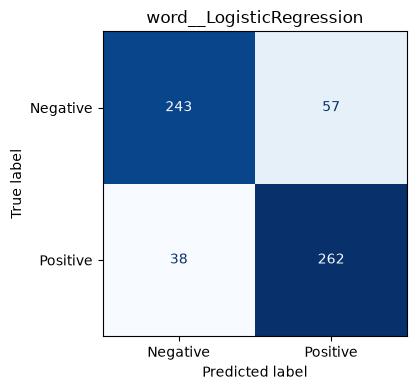

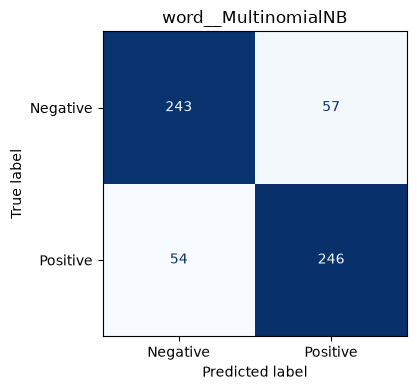

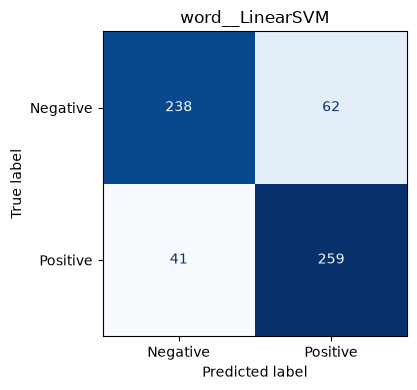

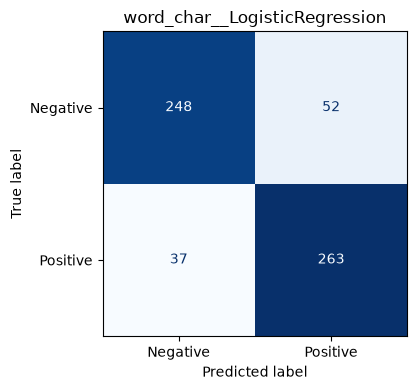

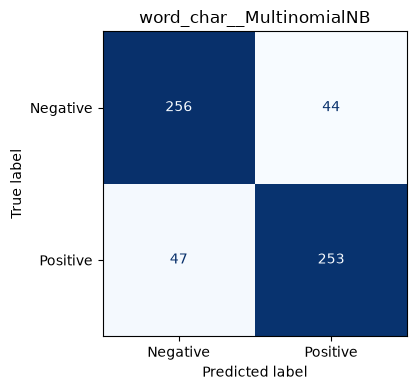

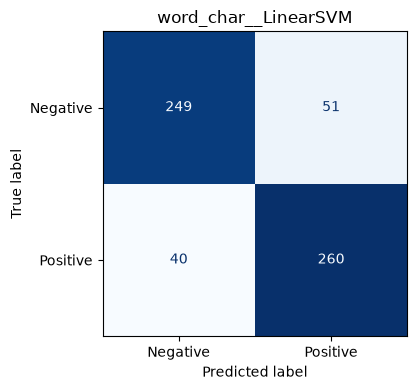

Confusion matrices saved: /home/anupam9k/ai_projects/03_Async_Market_Intelligence_&_Research_Agent/artifacts/sentiment/classical_ml/figures


In [11]:
for experiment_key, model in main_test_models.items():
    predictions = model.predict(X_test)

    fig, ax = plt.subplots(figsize=(5, 4))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=[0, 1],
        display_labels=["Negative", "Positive"],
        cmap="Blues",
        ax=ax,
        colorbar=False,
    )

    ax.set_title(experiment_key)
    plt.tight_layout()

    figure_path = FIGURES_DIR / f"{experiment_key}_confusion_matrix.png"
    fig.savefig(figure_path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("Confusion matrices saved:", FIGURES_DIR)


## 11. Cross-domain generalisation

We now evaluate the selected configurations on all three held-out-source
experiments.

For each experiment:
- The two non-held-out sources provide training and validation.
- The selected hyperparameters remain fixed from the main validation search.
- Training and validation are combined for final fitting.
- The held-out source is used only as the cross-domain test.

This evaluates transfer to a source that the model did not see during training.


In [12]:
cross_domain_results = []

for heldout_source in ["amazon", "imdb", "yelp"]:
    experiment_name = f"heldout_{heldout_source}"
    experiment_dir = CROSS_DOMAIN_DIR / experiment_name

    cross_train = pd.read_csv(experiment_dir / "train.csv")
    cross_validation = pd.read_csv(
        experiment_dir / "validation.csv"
    )
    cross_test = pd.read_csv(experiment_dir / "test.csv")

    cross_partitions = {
        "train": cross_train,
        "validation": cross_validation,
        "test": cross_test,
    }

    assert_no_group_leakage(cross_partitions)
    assert set(cross_test["source"]) == {heldout_source}

    X_cross_train = pd.concat(
        [cross_train, cross_validation],
        ignore_index=True,
    )["text"].astype(str).tolist()

    y_cross_train = pd.concat(
        [cross_train, cross_validation],
        ignore_index=True,
    )["label"].to_numpy()

    X_cross_test = cross_test["text"].astype(str).tolist()
    y_cross_test = cross_test["label"].to_numpy()

    for experiment_key, selected_model in best_estimators.items():
        final_model = clone(selected_model)

        fit_start = time.perf_counter()
        final_model.fit(X_cross_train, y_cross_train)
        fit_seconds = time.perf_counter() - fit_start

        metrics = calculate_metrics(
            final_model,
            X_cross_test,
            y_cross_test,
        )

        inference_ms = measure_inference_latency(
            final_model,
            X_cross_test,
        )

        cross_domain_results.append({
            "heldout_source": heldout_source,
            "experiment": experiment_key,
            "training_records": len(X_cross_train),
            "test_records": len(X_cross_test),
            "fit_seconds": fit_seconds,
            "inference_ms_per_sample": inference_ms,
            **metrics,
        })

cross_domain_results_df = pd.DataFrame(
    cross_domain_results
).sort_values(
    ["heldout_source", "f1_macro"],
    ascending=[True, False],
).reset_index(drop=True)

display(cross_domain_results_df.round(4))

cross_domain_results_df.to_csv(
    RESULTS_DIR / "cross_domain_results.csv",
    index=False,
)

print("Cross-domain results saved.")


,heldout_source,experiment,training_records,test_records,fit_seconds,inference_ms_per_sample,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,roc_auc,average_precision
0,amazon,word_char__LinearSVM,1999,1000,0.3656,0.0649,0.811,0.811,0.8120,0.811,0.8108,0.8826,0.8939
1,amazon,word_char__LogisticRegression,1999,1000,0.6645,0.0572,0.805,0.805,0.8059,0.805,0.8049,0.8847,0.8965
2,amazon,word__LogisticRegression,1999,1000,0.0489,0.0135,0.779,0.779,0.7790,0.779,0.7790,0.8728,0.8834
3,amazon,word__LinearSVM,1999,1000,0.0409,0.0103,0.776,0.776,0.7761,0.776,0.7760,0.8708,0.8813
4,amazon,word_char__MultinomialNB,1999,1000,0.2334,0.0577,0.773,0.773,0.7750,0.773,0.7726,0.8625,0.8743
5,amazon,word__MultinomialNB,1999,1000,0.0468,0.0097,0.761,0.761,0.7618,0.761,0.7608,0.8464,0.8535
6,imdb,word_char__MultinomialNB,1999,1000,0.1534,0.0795,0.736,0.736,0.7509,0.736,0.7320,0.8204,0.8335
7,imdb,word_char__LogisticRegression,1999,1000,0.6470,0.0759,0.732,0.732,0.7467,0.732,0.7280,0.8078,0.8242
8,imdb,word_char__LinearSVM,1999,1000,0.2516,0.0811,0.730,0.730,0.7426,0.730,0.7264,0.8076,0.8236
9,imdb,word__MultinomialNB,1999,1000,0.0353,0.0133,0.718,0.718,0.7291,0.718,0.7145,0.8012,0.8114


Cross-domain results saved.


## 12. Cross-domain comparison visualisation

Compare macro F1 across the three held-out sources.


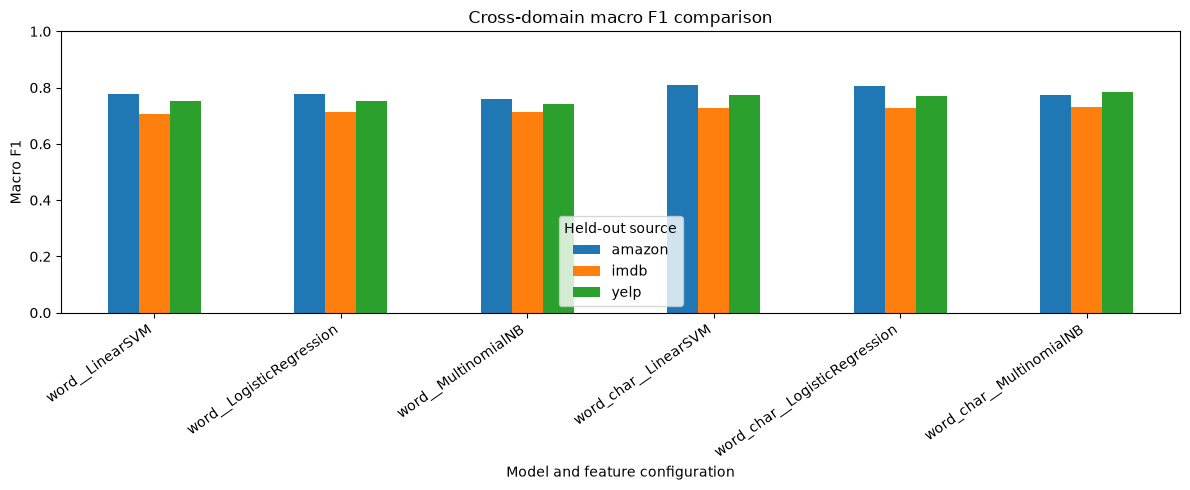

heldout_source,amazon,imdb,yelp
experiment,,,
word__LinearSVM,0.7760,0.7059,0.7509
word__LogisticRegression,0.7790,0.7117,0.7520
word__MultinomialNB,0.7608,0.7145,0.7434
word_char__LinearSVM,0.8108,0.7264,0.7750
word_char__LogisticRegression,0.8049,0.7280,0.7689
word_char__MultinomialNB,0.7726,0.7320,0.7842


In [13]:
cross_f1 = cross_domain_results_df.pivot(
    index="experiment",
    columns="heldout_source",
    values="f1_macro",
)

ax = cross_f1.plot(
    kind="bar",
    figsize=(12, 5),
)

ax.set_title("Cross-domain macro F1 comparison")
ax.set_xlabel("Model and feature configuration")
ax.set_ylabel("Macro F1")
ax.set_ylim(0, 1)
ax.legend(title="Held-out source")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

figure_path = FIGURES_DIR / "cross_domain_macro_f1.png"
plt.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close()

display(cross_f1.round(4))


## 13. Compare validation, main test and cross-domain results

The validation champion is determined before examining the test metrics.
The test and cross-domain tables are reported independently.

A large gap between main-test and cross-domain performance indicates that
randomly mixed source performance may overestimate real-world transfer.


In [14]:
validation_champion = selection_payload["validation_champion"]

champion_test = main_test_results_df[
    main_test_results_df["experiment"] == validation_champion
]

print("Validation-selected champion:", validation_champion)

if not champion_test.empty:
    print("\nMain test metrics:")
    display(
        champion_test[
            [
                "accuracy",
                "balanced_accuracy",
                "precision_macro",
                "recall_macro",
                "f1_macro",
                "roc_auc",
                "average_precision",
                "fit_seconds",
                "inference_ms_per_sample",
            ]
        ].round(4)
    )

print("\nChampion cross-domain results:")
display(
    cross_domain_results_df[
        cross_domain_results_df["experiment"] == validation_champion
    ].round(4)
)


Validation-selected champion: word_char__MultinomialNB

Main test metrics:


,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,roc_auc,average_precision,fit_seconds,inference_ms_per_sample
1,0.8483,0.8483,0.8484,0.8483,0.8483,0.9209,0.923,0.2456,0.0661



Champion cross-domain results:


,heldout_source,experiment,training_records,test_records,fit_seconds,inference_ms_per_sample,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,roc_auc,average_precision
4,amazon,word_char__MultinomialNB,1999,1000,0.2334,0.0577,0.773,0.773,0.7750,0.773,0.7726,0.8625,0.8743
6,imdb,word_char__MultinomialNB,1999,1000,0.1534,0.0795,0.736,0.736,0.7509,0.736,0.7320,0.8204,0.8335
12,yelp,word_char__MultinomialNB,2000,1000,0.2422,0.0707,0.785,0.785,0.7893,0.785,0.7842,0.8664,0.8815


## 14. Save experiment metadata and final report

No model binary is saved here. The final architecture will be chosen after
the classical ML and LSTM/BiLSTM experiments have both been completed.

The saved results provide reproducible evidence for the eventual model choice.


In [15]:
experiment_metadata = {
    "experiment": "classical_sentiment_model_comparison",
    "random_state": RANDOM_STATE,
    "input_partitions": [
        "data/processed/sentiment/train.csv",
        "data/processed/sentiment/validation.csv",
        "data/processed/sentiment/test.csv",
    ],
    "feature_configs": FEATURE_CONFIGS,
    "model_grids": MODEL_GRIDS,
    "selection_rule": (
        "Validation macro F1, then balanced accuracy, ROC-AUC, "
        "and inference latency."
    ),
    "validation_champion": validation_champion,
    "main_test_candidates": len(main_test_results_df),
    "cross_domain_experiments": [
        "heldout_amazon",
        "heldout_imdb",
        "heldout_yelp",
    ],
    "test_used_for_hyperparameter_selection": False,
    "model_artifacts_saved": False,
    "sklearn_version": sklearn.__version__,
}

(RESULTS_DIR / "experiment_metadata.json").write_text(
    json.dumps(experiment_metadata, indent=2),
    encoding="utf-8",
)

print("Saved experiment outputs:")
for file_path in sorted(RESULTS_DIR.rglob("*")):
    if file_path.is_file():
        print(
            f"{file_path.relative_to(PROJECT_ROOT)} "
            f"({file_path.stat().st_size:,} bytes)"
        )

print("\nCLASSICAL ML EXPERIMENT COMPLETED")


Saved experiment outputs:
artifacts/sentiment/classical_ml/best_candidate_config.json (2,041 bytes)
artifacts/sentiment/classical_ml/cross_domain_results.csv (3,306 bytes)
artifacts/sentiment/classical_ml/experiment_metadata.json (1,120 bytes)
artifacts/sentiment/classical_ml/figures/cross_domain_macro_f1.png (91,907 bytes)
artifacts/sentiment/classical_ml/figures/word__LinearSVM_confusion_matrix.png (26,379 bytes)
artifacts/sentiment/classical_ml/figures/word__LogisticRegression_confusion_matrix.png (27,858 bytes)
artifacts/sentiment/classical_ml/figures/word__MultinomialNB_confusion_matrix.png (26,253 bytes)
artifacts/sentiment/classical_ml/figures/word_char__LinearSVM_confusion_matrix.png (26,622 bytes)
artifacts/sentiment/classical_ml/figures/word_char__LogisticRegression_confusion_matrix.png (29,211 bytes)
artifacts/sentiment/classical_ml/figures/word_char__MultinomialNB_confusion_matrix.png (26,359 bytes)
artifacts/sentiment/classical_ml/main_test_by_source.csv (2,301 bytes)
arti

## 15. Research conclusions — complete after execution

Record the actual findings here.

### Questions
1. Which model/feature combination achieved the best validation macro F1?
2. Did word + character features improve validation performance?
3. Which model performed best on the untouched main test set?
4. Which model generalised best to Amazon, IMDb and Yelp when each was unseen?
5. Which source was most challenging?
6. What was the training and inference cost?
7. Did the best classical model maintain performance across all domains?

### Decision

The next research phase will compare the classical ML results with PyTorch
LSTM and BiLSTM models using the same main and cross-domain evaluation splits.


==========================================================================================================================================================

## Next phase: Classical ML model comparison
Now we can answer a very important question:

Does an LSTM actually outperform traditional machine-learning models on this sentiment dataset?

We'll compare:
Classical ML experiments
LR

Logistic Regression

TF-IDF + Logistic Regression



NB

Multinomial Naive Bayes

TF-IDF + MultinomialNB



SVM

Linear Support Vector Machine

TF-IDF + LinearSVC

## Step 1 — Prepare Notebook 03

In [2]:
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

from pathlib import Path
import time
import json

PROJECT_DIR = Path.cwd().parent.parent
DATA_DIR = Path(PROJECT_DIR /"data/processed/sentiment")

train_df = pd.read_csv(DATA_DIR / "train.csv")
val_df = pd.read_csv(DATA_DIR / "validation.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Training: (1920, 5)
Validation: (480, 5)
Test: (600, 5)


In [3]:
X_train = train_df["text"]
y_train = train_df["label"]

X_val = val_df["text"]
y_val = val_df["label"]

X_test = test_df["text"]
y_test = test_df["label"]

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

Training samples: 1920
Validation samples: 480
Test samples: 600


## Step 2 — Convert text into numerical features

In [4]:
# Configure word-level TF-IDF
word_vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    norm="l2",
    dtype=np.float32
)

# Learn vocabulary and transform training text
X_train_word_tfidf = word_vectorizer.fit_transform(X_train)

# Transform validation text using the learned vocabulary
X_val_word_tfidf = word_vectorizer.transform(X_val)

print("Training TF-IDF shape:", X_train_word_tfidf.shape)
print("Validation TF-IDF shape:", X_val_word_tfidf.shape)

print("\nVocabulary size:", len(word_vectorizer.vocabulary_))

# Inspect some learned features
print("\nFirst 25 learned features:")
print(word_vectorizer.get_feature_names_out()[:25])

# Calculate matrix density
train_density = (
    X_train_word_tfidf.nnz /
    (X_train_word_tfidf.shape[0] * X_train_word_tfidf.shape[1])
)

print(f"\nTraining matrix density: {train_density:.4%}")

Training TF-IDF shape: (1920, 3588)
Validation TF-IDF shape: (480, 3588)

Vocabulary size: 3588

First 25 learned features:
['10' '10 10' '10 minutes' '10 out' '100' '11' '12' '15' '15 minutes' '20'
 '2005' '25' '25 years' '30' '30 minutes' '40' '50' '90' 'ability' 'about'
 'about half' 'about it' 'about the' 'about this' 'above']

Training matrix density: 0.3698%


## Step 3 — Train Logistic Regression

In [6]:
SEED = 42

# Initialize Logistic Regression
lr_model = LogisticRegression(
    C=1.0,
    max_iter=2000,
    solver="liblinear",
    random_state=SEED
)

# Train on TF-IDF training features
start_time = time.perf_counter()

lr_model.fit(
    X_train_word_tfidf,
    y_train
)

training_time = time.perf_counter() - start_time

# Predict validation labels
val_predictions = lr_model.predict(
    X_val_word_tfidf
)

# Obtain decision scores for ranking metrics
val_scores = lr_model.decision_function(
    X_val_word_tfidf
)

# Calculate validation metrics
lr_results = {
    "Accuracy": accuracy_score(y_val, val_predictions),
    "Balanced Accuracy": balanced_accuracy_score(y_val, val_predictions),
    "Macro Precision": precision_score(
        y_val, val_predictions, average="macro"
    ),
    "Macro Recall": recall_score(
        y_val, val_predictions, average="macro"
    ),
    "Macro F1": f1_score(
        y_val, val_predictions, average="macro"
    ),
    "ROC-AUC": roc_auc_score(y_val, val_scores),
    "Average Precision": average_precision_score(
        y_val, val_scores
    ),
    "Training Time (seconds)": training_time
}

print("LOGISTIC REGRESSION — VALIDATION RESULTS")
print("-" * 45)

for metric, value in lr_results.items():
    print(f"{metric:<25}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, val_predictions))

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        val_predictions,
        target_names=["Negative", "Positive"],
        digits=4
    )
)

print("\nIterations:", lr_model.n_iter_)

LOGISTIC REGRESSION — VALIDATION RESULTS
---------------------------------------------
Accuracy                 : 0.8000
Balanced Accuracy        : 0.8000
Macro Precision          : 0.8005
Macro Recall             : 0.8000
Macro F1                 : 0.7999
ROC-AUC                  : 0.8827
Average Precision        : 0.8872
Training Time (seconds)  : 0.0381

Confusion Matrix:
[[187  53]
 [ 43 197]]

Classification Report:
              precision    recall  f1-score   support

    Negative     0.8130    0.7792    0.7957       240
    Positive     0.7880    0.8208    0.8041       240

    accuracy                         0.8000       480
   macro avg     0.8005    0.8000    0.7999       480
weighted avg     0.8005    0.8000    0.7999       480


Iterations: [4]


### Tune Logistic Regression

In [7]:
C_VALUES = [0.01, 0.1, 1.0, 10.0, 100.0]

lr_tuning_results = []

for C in C_VALUES:

    model = LogisticRegression(
        C=C,
        max_iter=2000,
        solver="liblinear",
        random_state=SEED
    )

    start_time = time.perf_counter()

    model.fit(X_train_word_tfidf, y_train)

    training_time = time.perf_counter() - start_time

    predictions = model.predict(X_val_word_tfidf)
    scores = model.decision_function(X_val_word_tfidf)

    lr_tuning_results.append({
        "C": C,
        "accuracy": accuracy_score(y_val, predictions),
        "macro_f1": f1_score(
            y_val, predictions, average="macro"
        ),
        "roc_auc": roc_auc_score(y_val, scores),
        "training_time": training_time
    })

lr_tuning_df = pd.DataFrame(lr_tuning_results)

display(
    lr_tuning_df.sort_values(
        "macro_f1",
        ascending=False
    ).reset_index(drop=True).round(4)
)

,C,accuracy,macro_f1,roc_auc,training_time
0,10.00,0.8125,0.8123,0.8920,0.0044
1,100.00,0.8042,0.8041,0.8841,0.0065
2,1.00,0.8000,0.7999,0.8827,0.0030
3,0.10,0.7833,0.7833,0.8584,0.0023
4,0.01,0.7771,0.7771,0.8499,0.0044


## 2. Next model — Multinomial Naive Bayes

### Step 1 — Train the baseline

In [8]:
nb_model = MultinomialNB(
    alpha=1.0
)

start_time = time.perf_counter()

nb_model.fit(
    X_train_word_tfidf,
    y_train
)

nb_training_time = time.perf_counter() - start_time

# Validation predictions
nb_predictions = nb_model.predict(X_val_word_tfidf)

nb_probabilities = nb_model.predict_proba(
    X_val_word_tfidf
)[:, 1]

# Calculate metrics
nb_results = {
    "Accuracy": accuracy_score(y_val, nb_predictions),
    "Balanced Accuracy": balanced_accuracy_score(y_val, nb_predictions),
    "Macro Precision": precision_score(
        y_val, nb_predictions, average="macro"
    ),
    "Macro Recall": recall_score(
        y_val, nb_predictions, average="macro"
    ),
    "Macro F1": f1_score(
        y_val, nb_predictions, average="macro"
    ),
    "ROC-AUC": roc_auc_score(y_val, nb_probabilities),
    "Average Precision": average_precision_score(
        y_val, nb_probabilities
    ),
    "Training Time (seconds)": nb_training_time
}

print("MULTINOMIAL NAIVE BAYES — VALIDATION RESULTS")
print("-" * 50)

for metric, value in nb_results.items():
    print(f"{metric:<25}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, nb_predictions))

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        nb_predictions,
        target_names=["Negative", "Positive"],
        digits=4
    )
)

MULTINOMIAL NAIVE BAYES — VALIDATION RESULTS
--------------------------------------------------
Accuracy                 : 0.8146
Balanced Accuracy        : 0.8146
Macro Precision          : 0.8158
Macro Recall             : 0.8146
Macro F1                 : 0.8144
ROC-AUC                  : 0.9024
Average Precision        : 0.9145
Training Time (seconds)  : 0.0061

Confusion Matrix:
[[188  52]
 [ 37 203]]

Classification Report:
              precision    recall  f1-score   support

    Negative     0.8356    0.7833    0.8086       240
    Positive     0.7961    0.8458    0.8202       240

    accuracy                         0.8146       480
   macro avg     0.8158    0.8146    0.8144       480
weighted avg     0.8158    0.8146    0.8144       480



### Tune Multinomial Naive Bayes

In [9]:
ALPHA_VALUES = [
    0.001, 0.01, 0.05, 0.1,
    0.25, 0.5, 1.0, 2.0, 5.0, 10.0
]

nb_tuning_results = []

for alpha in ALPHA_VALUES:

    model = MultinomialNB(alpha=alpha)

    start_time = time.perf_counter()

    model.fit(X_train_word_tfidf, y_train)

    training_time = time.perf_counter() - start_time

    predictions = model.predict(X_val_word_tfidf)

    probabilities = model.predict_proba(
        X_val_word_tfidf
    )[:, 1]

    nb_tuning_results.append({
        "alpha": alpha,
        "accuracy": accuracy_score(y_val, predictions),
        "macro_f1": f1_score(
            y_val, predictions, average="macro"
        ),
        "roc_auc": roc_auc_score(y_val, probabilities),
        "average_precision": average_precision_score(
            y_val, probabilities
        ),
        "training_time": training_time
    })

nb_tuning_df = pd.DataFrame(nb_tuning_results)

display(
    nb_tuning_df.sort_values(
        "macro_f1",
        ascending=False
    ).reset_index(drop=True).round(4)
)

,alpha,accuracy,macro_f1,roc_auc,average_precision,training_time
0,0.050,0.8312,0.8311,0.9033,0.9122,0.0025
1,0.100,0.8271,0.8270,0.9042,0.9144,0.0024
2,0.500,0.8271,0.8268,0.9054,0.9176,0.0019
3,0.250,0.8229,0.8226,0.9062,0.9179,0.0024
4,1.000,0.8146,0.8144,0.9024,0.9145,0.0023
5,0.010,0.8104,0.8103,0.8948,0.9012,0.0017
6,0.001,0.8042,0.8040,0.8837,0.8871,0.0064
7,2.000,0.8042,0.8040,0.8983,0.9102,0.0018
8,5.000,0.7896,0.7894,0.8892,0.8997,0.0021
9,10.000,0.7833,0.7832,0.8794,0.8876,0.0028


## 3. Next: Linear SVM

In [10]:
svm_model = LinearSVC(
    C=1.0,
    max_iter=5000,
    random_state=SEED
)

start_time = time.perf_counter()

svm_model.fit(
    X_train_word_tfidf,
    y_train
)

svm_training_time = time.perf_counter() - start_time

# Validation predictions
svm_predictions = svm_model.predict(X_val_word_tfidf)

# Decision scores for ranking metrics
svm_scores = svm_model.decision_function(X_val_word_tfidf)

# Calculate metrics
svm_results = {
    "Accuracy": accuracy_score(y_val, svm_predictions),
    "Balanced Accuracy": balanced_accuracy_score(y_val, svm_predictions),
    "Macro Precision": precision_score(
        y_val, svm_predictions, average="macro"
    ),
    "Macro Recall": recall_score(
        y_val, svm_predictions, average="macro"
    ),
    "Macro F1": f1_score(
        y_val, svm_predictions, average="macro"
    ),
    "ROC-AUC": roc_auc_score(y_val, svm_scores),
    "Average Precision": average_precision_score(
        y_val, svm_scores
    ),
    "Training Time (seconds)": svm_training_time
}

print("LINEAR SVM — VALIDATION RESULTS")
print("-" * 45)

for metric, value in svm_results.items():
    print(f"{metric:<25}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, svm_predictions))

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        svm_predictions,
        target_names=["Negative", "Positive"],
        digits=4
    )
)

LINEAR SVM — VALIDATION RESULTS
---------------------------------------------
Accuracy                 : 0.8229
Balanced Accuracy        : 0.8229
Macro Precision          : 0.8242
Macro Recall             : 0.8229
Macro F1                 : 0.8227
ROC-AUC                  : 0.8918
Average Precision        : 0.9020
Training Time (seconds)  : 0.0149

Confusion Matrix:
[[190  50]
 [ 35 205]]

Classification Report:
              precision    recall  f1-score   support

    Negative     0.8444    0.7917    0.8172       240
    Positive     0.8039    0.8542    0.8283       240

    accuracy                         0.8229       480
   macro avg     0.8242    0.8229    0.8227       480
weighted avg     0.8242    0.8229    0.8227       480



### Tune Linear SVM

In [11]:
SVM_C_VALUES = [0.01, 0.1, 1.0, 10.0, 100.0]

svm_tuning_results = []

for C in SVM_C_VALUES:

    model = LinearSVC(
        C=C,
        max_iter=5000,
        random_state=SEED
    )

    start_time = time.perf_counter()

    model.fit(X_train_word_tfidf, y_train)

    training_time = time.perf_counter() - start_time

    predictions = model.predict(X_val_word_tfidf)
    scores = model.decision_function(X_val_word_tfidf)

    svm_tuning_results.append({
        "C": C,
        "accuracy": accuracy_score(y_val, predictions),
        "macro_f1": f1_score(
            y_val, predictions, average="macro"
        ),
        "roc_auc": roc_auc_score(y_val, scores),
        "average_precision": average_precision_score(
            y_val, scores
        ),
        "training_time": training_time
    })

svm_tuning_df = pd.DataFrame(svm_tuning_results)

display(
    svm_tuning_df.sort_values(
        "macro_f1",
        ascending=False
    ).reset_index(drop=True).round(4)
)

,C,accuracy,macro_f1,roc_auc,average_precision,training_time
0,1.00,0.8229,0.8227,0.8918,0.9020,0.0039
1,0.10,0.7979,0.7978,0.8826,0.8863,0.0023
2,0.01,0.7854,0.7854,0.8566,0.8590,0.0049
3,100.00,0.7833,0.7833,0.8627,0.8732,0.0842
4,10.00,0.7833,0.7833,0.8713,0.8844,0.0133


### Classical ML leaderboard


| Model | Best configuration | Validation Macro F1 |
| :--- | :--- | :--- |
| **Multinomial NB** | α = 0.05 | 0.8311 |
| **Linear SVM** | C = 1.0 | 0.8227 |
| **Logistic Regression** | C = 10.0 | 0.8123 |

## Next experiment: combine word and character TF-IDF

### Step 1 — Build the combined feature extractor

In [12]:
from sklearn.pipeline import FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer

# Word-level TF-IDF
word_vectorizer_combined = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    norm="l2",
    dtype=np.float32
)

# Character-level TF-IDF
char_vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    min_df=2,
    max_features=30000,
    sublinear_tf=True,
    norm="l2",
    dtype=np.float32
)

# Combine both feature extractors
combined_vectorizer = FeatureUnion([
    ("word", word_vectorizer_combined),
    ("char", char_vectorizer)
])

# Fit using training data only
X_train_combined = combined_vectorizer.fit_transform(X_train)

# Transform validation data
X_val_combined = combined_vectorizer.transform(X_val)

print("Word vocabulary size:",
      len(word_vectorizer_combined.vocabulary_))

print("Character vocabulary size:",
      len(char_vectorizer.vocabulary_))

print("\nCombined training shape:", X_train_combined.shape)
print("Combined validation shape:", X_val_combined.shape)

combined_density = (
    X_train_combined.nnz /
    (X_train_combined.shape[0] * X_train_combined.shape[1])
)

print(f"Combined matrix density: {combined_density:.4%}")

Word vocabulary size: 3588
Character vocabulary size: 15539

Combined training shape: (1920, 19127)
Combined validation shape: (480, 19127)
Combined matrix density: 0.6463%


### Step 2 — Train all three classifiers on combined features

In [13]:
combined_models = {
    "Logistic Regression": LogisticRegression(
        C=10.0,
        max_iter=2000,
        solver="liblinear",
        random_state=SEED
    ),

    "Multinomial NB": MultinomialNB(
        alpha=0.05
    ),

    "Linear SVM": LinearSVC(
        C=1.0,
        max_iter=5000,
        random_state=SEED
    )
}

combined_results = []

for model_name, model in combined_models.items():

    print(f"\nTraining: {model_name}")

    start_time = time.perf_counter()

    model.fit(X_train_combined, y_train)

    training_time = time.perf_counter() - start_time

    # Predict validation labels
    predictions = model.predict(X_val_combined)

    # Obtain continuous scores for ranking metrics
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_val_combined)[:, 1]
    else:
        scores = model.decision_function(X_val_combined)

    combined_results.append({
        "model": model_name,
        "accuracy": accuracy_score(y_val, predictions),
        "macro_f1": f1_score(
            y_val, predictions, average="macro"
        ),
        "roc_auc": roc_auc_score(y_val, scores),
        "average_precision": average_precision_score(
            y_val, scores
        ),
        "training_time": training_time
    })

combined_results_df = pd.DataFrame(combined_results)

display(
    combined_results_df.sort_values(
        "macro_f1",
        ascending=False
    ).reset_index(drop=True).round(4)
)


Training: Logistic Regression

Training: Multinomial NB

Training: Linear SVM


,model,accuracy,macro_f1,roc_auc,average_precision,training_time
0,Multinomial NB,0.8375,0.8375,0.9198,0.9255,0.0037
1,Logistic Regression,0.8292,0.8291,0.9167,0.9272,1.3522
2,Linear SVM,0.8188,0.8186,0.9134,0.9235,0.0323


### Tune the combined-feature Naive Bayes

In [14]:
COMBINED_ALPHA_VALUES = [
    0.005, 0.01, 0.025, 0.05,
    0.075, 0.1, 0.25, 0.5, 1.0
]

combined_nb_tuning = []

for alpha in COMBINED_ALPHA_VALUES:

    model = MultinomialNB(alpha=alpha)

    start_time = time.perf_counter()

    model.fit(X_train_combined, y_train)

    training_time = time.perf_counter() - start_time

    predictions = model.predict(X_val_combined)

    probabilities = model.predict_proba(
        X_val_combined
    )[:, 1]

    combined_nb_tuning.append({
        "alpha": alpha,
        "accuracy": accuracy_score(y_val, predictions),
        "macro_f1": f1_score(
            y_val, predictions, average="macro"
        ),
        "roc_auc": roc_auc_score(y_val, probabilities),
        "average_precision": average_precision_score(
            y_val, probabilities
        ),
        "training_time": training_time
    })

combined_nb_tuning_df = pd.DataFrame(combined_nb_tuning)

display(
    combined_nb_tuning_df.sort_values(
        "macro_f1",
        ascending=False
    ).reset_index(drop=True).round(4)
)

,alpha,accuracy,macro_f1,roc_auc,average_precision,training_time
0,0.100,0.8438,0.8437,0.9218,0.9290,0.0027
1,0.075,0.8417,0.8416,0.9211,0.9276,0.0024
2,0.050,0.8375,0.8375,0.9198,0.9255,0.0029
3,0.250,0.8375,0.8374,0.9236,0.9327,0.0024
4,0.500,0.8312,0.8312,0.9227,0.9330,0.0025
5,0.010,0.8292,0.8291,0.9126,0.9152,0.0033
6,0.025,0.8271,0.8270,0.9174,0.9219,0.0042
7,0.005,0.8208,0.8207,0.9090,0.9099,0.0056
8,1.000,0.8188,0.8186,0.9195,0.9313,0.0030


### Tune Logistic Regression on combined features

In [15]:
COMBINED_LR_C_VALUES = [0.1, 1.0, 10.0, 30.0, 100.0]

combined_lr_tuning = []

for C in COMBINED_LR_C_VALUES:

    model = LogisticRegression(
        C=C,
        max_iter=3000,
        solver="liblinear",
        random_state=SEED
    )

    start_time = time.perf_counter()

    model.fit(X_train_combined, y_train)

    training_time = time.perf_counter() - start_time

    predictions = model.predict(X_val_combined)
    scores = model.decision_function(X_val_combined)

    combined_lr_tuning.append({
        "C": C,
        "accuracy": accuracy_score(y_val, predictions),
        "macro_f1": f1_score(
            y_val, predictions, average="macro"
        ),
        "roc_auc": roc_auc_score(y_val, scores),
        "average_precision": average_precision_score(
            y_val, scores
        ),
        "training_time": training_time
    })

combined_lr_tuning_df = pd.DataFrame(combined_lr_tuning)

display(
    combined_lr_tuning_df.sort_values(
        "macro_f1",
        ascending=False
    ).reset_index(drop=True).round(4)
)

,C,accuracy,macro_f1,roc_auc,average_precision,training_time
0,1.0,0.8292,0.8291,0.9170,0.9262,0.5916
1,10.0,0.8292,0.8291,0.9167,0.9272,1.0125
2,30.0,0.8167,0.8165,0.9147,0.9255,1.5406
3,100.0,0.8125,0.8124,0.9128,0.9238,0.6317
4,0.1,0.8042,0.8042,0.8934,0.9034,0.3432


## Final training — combine training and validation data

In [16]:
# Combine training and validation datasets
train_val_df = pd.concat(
    [train_df, val_df],
    ignore_index=True
)

# Extract text and labels
X_train_val = train_val_df["text"]
y_train_val = train_val_df["label"]

# Retain the untouched test data
X_test_final = test_df["text"]
y_test_final = test_df["label"]

print("Final training samples:", len(X_train_val))
print("Final test samples:", len(X_test_final))

print("\nTraining label distribution:")
print(y_train_val.value_counts().sort_index())

print("\nTest label distribution:")
print(y_test_final.value_counts().sort_index())

Final training samples: 2400
Final test samples: 600

Training label distribution:
label
0    1200
1    1200
Name: count, dtype: int64

Test label distribution:
label
0    300
1    300
Name: count, dtype: int64


### Rebuild the final TF-IDF features

In [17]:
# 1. Final word-level TF-IDF vectorizer
final_word_vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    norm="l2",
    dtype=np.float32
)

X_train_val_word = final_word_vectorizer.fit_transform(
    X_train_val
)

X_test_word = final_word_vectorizer.transform(
    X_test_final
)


# 2. Final combined word + character TF-IDF
final_combined_vectorizer = FeatureUnion([
    (
        "word",
        TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True,
            norm="l2",
            dtype=np.float32
        )
    ),
    (
        "char",
        TfidfVectorizer(
            analyzer="char_wb",
            ngram_range=(3, 5),
            min_df=2,
            max_features=30000,
            sublinear_tf=True,
            norm="l2",
            dtype=np.float32
        )
    )
])

X_train_val_combined = final_combined_vectorizer.fit_transform(
    X_train_val
)

X_test_combined = final_combined_vectorizer.transform(
    X_test_final
)


# 3. Inspect feature dimensions
print("WORD-LEVEL FEATURES")
print("Training:", X_train_val_word.shape)
print("Test:", X_test_word.shape)
print(
    "Vocabulary:",
    len(final_word_vectorizer.vocabulary_)
)

print("\nCOMBINED FEATURES")
print("Training:", X_train_val_combined.shape)
print("Test:", X_test_combined.shape)

print(
    "Word vocabulary:",
    len(
        final_combined_vectorizer
        .transformer_list[0][1].vocabulary_
    )
)

print(
    "Character vocabulary:",
    len(
        final_combined_vectorizer
        .transformer_list[1][1].vocabulary_
    )
)

WORD-LEVEL FEATURES
Training: (2400, 4525)
Test: (600, 4525)
Vocabulary: 4525

COMBINED FEATURES
Training: (2400, 22341)
Test: (600, 22341)
Word vocabulary: 4525
Character vocabulary: 17816


## Train and evaluate the three final classical models

In [18]:
final_classical_models = {
    "Logistic Regression": (
        LogisticRegression(
            C=1.0,
            max_iter=3000,
            solver="liblinear",
            random_state=SEED
        ),
        X_train_val_combined,
        X_test_combined
    ),

    "Multinomial NB": (
        MultinomialNB(alpha=0.10),
        X_train_val_combined,
        X_test_combined
    ),

    "Linear SVM": (
        LinearSVC(
            C=1.0,
            max_iter=5000,
            random_state=SEED
        ),
        X_train_val_word,
        X_test_word
    )
}

final_classical_results = []
final_classical_predictions = {}

for model_name, (model, X_train_features, X_test_features) in (
    final_classical_models.items()
):

    print(f"\nTraining {model_name}...")

    # Training
    start_time = time.perf_counter()

    model.fit(X_train_features, y_train_val)

    training_time = time.perf_counter() - start_time

    # Test prediction
    start_time = time.perf_counter()

    predictions = model.predict(X_test_features)

    inference_time = time.perf_counter() - start_time

    # Continuous scores for ranking metrics
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test_features)[:, 1]
    else:
        scores = model.decision_function(X_test_features)

    # Save predictions for further analysis
    final_classical_predictions[model_name] = {
        "predictions": predictions,
        "scores": scores
    }

    # Calculate test metrics
    final_classical_results.append({
        "model": model_name,
        "accuracy": accuracy_score(y_test_final, predictions),
        "balanced_accuracy": balanced_accuracy_score(
            y_test_final, predictions
        ),
        "macro_precision": precision_score(
            y_test_final, predictions,
            average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            y_test_final, predictions,
            average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            y_test_final, predictions,
            average="macro", zero_division=0
        ),
        "roc_auc": roc_auc_score(y_test_final, scores),
        "average_precision": average_precision_score(
            y_test_final, scores
        ),
        "training_time": training_time,
        "inference_time": inference_time
    })

    print(
        f"Completed | Training: {training_time:.4f}s | "
        f"Inference: {inference_time:.4f}s"
    )


# Final comparison table
final_classical_results_df = pd.DataFrame(
    final_classical_results
)

display(
    final_classical_results_df.sort_values(
        "macro_f1",
        ascending=False
    ).reset_index(drop=True).round(4)
)


Training Logistic Regression...
Completed | Training: 0.6341s | Inference: 0.0012s

Training Multinomial NB...
Completed | Training: 0.0054s | Inference: 0.0008s

Training Linear SVM...
Completed | Training: 0.0086s | Inference: 0.0005s


,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,roc_auc,average_precision,training_time,inference_time
0,Logistic Regression,0.8500,0.8500,0.8506,0.8500,0.8499,0.9262,0.9306,0.6341,0.0012
1,Multinomial NB,0.8467,0.8467,0.8467,0.8467,0.8467,0.9151,0.9156,0.0054,0.0008
2,Linear SVM,0.8250,0.8250,0.8254,0.8250,0.8249,0.9113,0.9158,0.0086,0.0005


### Inspect confusion matrices

In [19]:
for model_name, result in final_classical_predictions.items():

    print(f"\n{model_name}")
    print("-" * 45)

    predictions = result["predictions"]

    print(
        confusion_matrix(
            y_test_final,
            predictions
        )
    )

    print(
        classification_report(
            y_test_final,
            predictions,
            target_names=["Negative", "Positive"],
            digits=4,
            zero_division=0
        )
    )


Logistic Regression
---------------------------------------------
[[249  51]
 [ 39 261]]
              precision    recall  f1-score   support

    Negative     0.8646    0.8300    0.8469       300
    Positive     0.8365    0.8700    0.8529       300

    accuracy                         0.8500       600
   macro avg     0.8506    0.8500    0.8499       600
weighted avg     0.8506    0.8500    0.8499       600


Multinomial NB
---------------------------------------------
[[255  45]
 [ 47 253]]
              precision    recall  f1-score   support

    Negative     0.8444    0.8500    0.8472       300
    Positive     0.8490    0.8433    0.8462       300

    accuracy                         0.8467       600
   macro avg     0.8467    0.8467    0.8467       600
weighted avg     0.8467    0.8467    0.8467       600


Linear SVM
---------------------------------------------
[[242  58]
 [ 47 253]]
              precision    recall  f1-score   support

    Negative     0.8374    0.8067  

### Next step — Compare performance by review source

In [20]:
source_comparison = []

test_sources = test_df["source"].to_numpy()

for model_name, result in final_classical_predictions.items():

    predictions = result["predictions"]
    scores = result["scores"]

    for source in sorted(test_df["source"].unique()):

        mask = test_sources == source

        source_y_true = y_test_final.to_numpy()[mask]
        source_y_pred = predictions[mask]
        source_scores = scores[mask]

        source_comparison.append({
            "model": model_name,
            "source": source,
            "samples": int(mask.sum()),
            "accuracy": accuracy_score(
                source_y_true, source_y_pred
            ),
            "macro_f1": f1_score(
                source_y_true,
                source_y_pred,
                average="macro"
            ),
            "roc_auc": roc_auc_score(
                source_y_true, source_scores
            )
        })

source_comparison_df = pd.DataFrame(source_comparison)

display(
    source_comparison_df.sort_values(
        ["source", "macro_f1"],
        ascending=[True, False]
    ).round(4)
)

,model,source,samples,accuracy,macro_f1,roc_auc
3,Multinomial NB,amazon,200,0.870,0.8700,0.9264
6,Linear SVM,amazon,200,0.865,0.8649,0.9242
0,Logistic Regression,amazon,200,0.860,0.8596,0.9377
4,Multinomial NB,imdb,200,0.815,0.8146,0.8850
1,Logistic Regression,imdb,200,0.795,0.7950,0.8755
7,Linear SVM,imdb,200,0.755,0.7548,0.8640
2,Logistic Regression,yelp,200,0.895,0.8950,0.9575
8,Linear SVM,yelp,200,0.855,0.8550,0.9397
5,Multinomial NB,yelp,200,0.855,0.8548,0.9334


## Package the trained model

In [21]:
import joblib
import json
from pathlib import Path

# 1. Retrieve the already-trained final model
selected_model_name = "Logistic Regression"

selected_model = final_classical_models[
    selected_model_name
][0]

# 2. Define artifact directory
artifact_dir = Path(
    "artifacts/sentiment/classical_ml"
)

artifact_dir.mkdir(
    parents=True,
    exist_ok=True
)

# 3. Create model bundle
model_bundle = {
    "model": selected_model,
    "vectorizer": final_combined_vectorizer,
    "label_mapping": {
        0: "negative",
        1: "positive"
    }
}

# 4. Save model and vectorizer together
model_path = (
    artifact_dir /
    "logistic_regression_word_char.joblib"
)

joblib.dump(
    model_bundle,
    model_path,
    compress=3
)

print("Model artifact saved successfully.")
print("Location:", model_path)
print(
    "File size:",
    round(model_path.stat().st_size / (1024 ** 2), 2),
    "MB"
)

Model artifact saved successfully.
Location: artifacts/sentiment/classical_ml/logistic_regression_word_char.joblib
File size: 0.3 MB


## Save model metadata

In [22]:
result_row = (
    final_classical_results_df
    .loc[
        final_classical_results_df["model"]
        == selected_model_name
    ]
    .iloc[0]
)

metadata = {
    "model_name": "Logistic Regression",
    "model_type": "classical_ml",
    "feature_extraction": "word_char_tfidf",
    "hyperparameters": {
        "C": 1.0,
        "solver": "liblinear",
        "max_iter": 3000
    },
    "training_samples": len(X_train_val),
    "training_sources": sorted(
        train_val_df["source"].unique().tolist()
    ),
    "label_mapping": {
        "0": "negative",
        "1": "positive"
    },
    "test_metrics": {
        metric: float(result_row[metric])
        for metric in [
            "accuracy",
            "balanced_accuracy",
            "macro_precision",
            "macro_recall",
            "macro_f1",
            "roc_auc",
            "average_precision"
        ]
    }
}

metadata_path = artifact_dir / "metadata.json"

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4)

print("Metadata saved:", metadata_path)

Metadata saved: artifacts/sentiment/classical_ml/metadata.json


## Verify the saved artifact

In [23]:
# 1. Load the saved artifact
loaded_bundle = joblib.load(model_path)

loaded_model = loaded_bundle["model"]
loaded_vectorizer = loaded_bundle["vectorizer"]
loaded_label_mapping = loaded_bundle["label_mapping"]

# 2. Transform raw test text using the loaded vectorizer
X_test_reloaded = loaded_vectorizer.transform(
    X_test_final
)

# 3. Generate predictions
reloaded_predictions = loaded_model.predict(
    X_test_reloaded
)

reloaded_probabilities = loaded_model.predict_proba(
    X_test_reloaded
)[:, 1]

# 4. Compare against original predictions
original_predictions = (
    final_classical_predictions["Logistic Regression"]["predictions"]
)

original_probabilities = (
    final_classical_predictions["Logistic Regression"]["scores"]
)

predictions_match = np.array_equal(
    original_predictions,
    reloaded_predictions
)

probabilities_match = np.allclose(
    original_probabilities,
    reloaded_probabilities,
    atol=1e-7
)

print("MODEL RESTORATION VERIFICATION")
print("-" * 45)

print("Model type:", type(loaded_model).__name__)
print("Vectorizer features:", X_test_reloaded.shape[1])
print("Predictions match:", predictions_match)
print("Probabilities match:", probabilities_match)

print(
    "Maximum probability difference:",
    np.max(
        np.abs(
            original_probabilities - reloaded_probabilities
        )
    )
)

assert predictions_match
assert probabilities_match

print("\nArtifact verification PASSED.")

MODEL RESTORATION VERIFICATION
---------------------------------------------
Model type: LogisticRegression
Vectorizer features: 22341
Predictions match: True
Probabilities match: True
Maximum probability difference: 0.0

Artifact verification PASSED.
